<a href="https://colab.research.google.com/github/pradityaputra888-lab/latihan-machine-learning/blob/main/pertemuan9/Bab09_Ensemble.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bab 9 — Ensemble Learning: Random Forest, Bagging, dan Boosting

**Dataset:** Wine (bawaan Scikit-learn) · **Isi notebook:** Praktikum 9.1–9.5 (kode modul), Latihan Praktikum 1 (Praktikum 9.6), dan Latihan Praktikum 2 (perbandingan empat model dengan Stratified k-Fold CV).

> Jalankan sel dari atas ke bawah secara berurutan.

## 9.11 Implementasi Python

### Praktikum 9.1 Persiapan Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score

print("Library berhasil dimuat.")

Library berhasil dimuat.


### Praktikum 9.2 Import Dataset

In [2]:
data = load_wine(as_frame=True)
X, y = data.data, data.target
print("Ukuran data    :", X.shape)
print("Distribusi kelas:", np.bincount(y).tolist())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

Ukuran data    : (178, 13)
Distribusi kelas: [59, 71, 48]


### Praktikum 9.3 Preprocessing dan Training Model
Model berbasis pohon tidak memerlukan *scaling*, sehingga data langsung dipakai.

In [3]:
rf = RandomForestClassifier(n_estimators=300, oob_score=True, random_state=42)
rf.fit(X_train, y_train)

ada = AdaBoostClassifier(n_estimators=100, random_state=42)
ada.fit(X_train, y_train)

gb = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42)
gb.fit(X_train, y_train)

tree_tunggal = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
print("Keempat model berhasil dilatih.")

Keempat model berhasil dilatih.


### Praktikum 9.4 Evaluasi

In [4]:
print("OOB Score Random Forest:", round(rf.oob_score_, 3))

for nama, model in [("Decision Tree Tunggal", tree_tunggal),
                    ("Random Forest", rf),
                    ("AdaBoost", ada),
                    ("Gradient Boosting", gb)]:
    acc = accuracy_score(y_test, model.predict(X_test))
    print(f"{nama}: Akurasi Test = {acc:.3f}")

OOB Score Random Forest: 0.979
Decision Tree Tunggal: Akurasi Test = 0.944
Random Forest: Akurasi Test = 1.000
AdaBoost: Akurasi Test = 0.917
Gradient Boosting: Akurasi Test = 0.944


### Praktikum 9.5 Visualisasi — Feature Importance

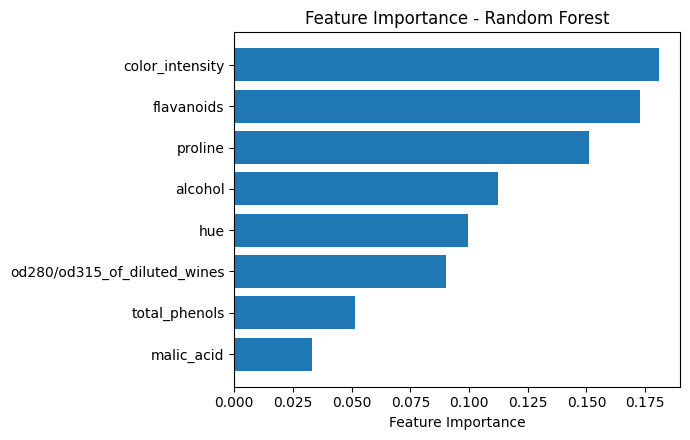

In [5]:
importances = rf.feature_importances_
idx = np.argsort(importances)[::-1][:8]
plt.figure(figsize=(7, 4.5))
plt.barh([data.feature_names[i] for i in idx][::-1], importances[idx][::-1])
plt.xlabel("Feature Importance")
plt.title("Feature Importance - Random Forest")
plt.tight_layout()
plt.show()

### Interpretasi (Praktikum 9.1–9.5)
- **Perbandingan model (data uji 36 sampel):** Random Forest 1,000 · Decision Tree 0,944 · Gradient Boosting 0,944 · AdaBoost 0,917. Random Forest salah nol sampel, sedangkan model lain salah 2–3 sampel. Karena data ujinya kecil, setiap kesalahan bernilai ≈2,8 poin persentase, sehingga hasil ini akan dikonfirmasi dengan cross-validation pada Latihan 2.
- **OOB Score = 0,979.** Estimasi ini dihitung tanpa data uji (memakai sampel yang tidak ikut ter-*bootstrap* pada tiap pohon) dan konsisten dengan akurasi uji, tanda bahwa Random Forest tidak overfitting.
- **Feature importance:** `color_intensity` (0,181), `flavanoids` (0,173), dan `proline` (0,151) adalah tiga fitur terpenting dan bersama-sama menyumbang sekitar separuh total importance. Ketiganya sesuai dengan intuisi domain: warna, senyawa fenolik, dan kandungan asam amino pembeda jenis anggur.
- **Mengapa Random Forest unggul di sini:** satu pohon bervarians tinggi, sedangkan rata-rata banyak pohon yang dilatih pada *bootstrap* dan subset fitur berbeda menurunkan varians tanpa menaikkan bias. Boosting menurunkan bias, tetapi dengan data sekecil dan sebersih ini (178 sampel) bias bukan masalah utama.

---
## 9.12 Latihan Praktikum

### Latihan 1 — Pengaruh `n_estimators` (Praktikum 9.6)
**Tujuan:** mengamati pengaruh jumlah pohon terhadap performa dan OOB score Random Forest.

n_estimators=10: OOB=0.951, Test Acc=1.000
n_estimators=50: OOB=0.972, Test Acc=1.000
n_estimators=100: OOB=0.979, Test Acc=1.000
n_estimators=300: OOB=0.979, Test Acc=1.000
n_estimators=500: OOB=0.979, Test Acc=1.000


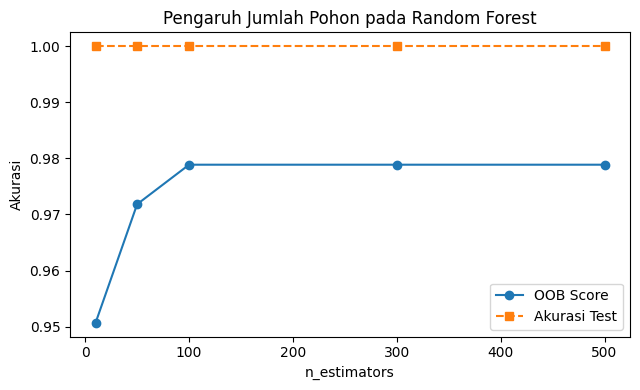

,n_estimators,OOB Score,Akurasi Test
0,10,0.951,1.0
1,50,0.972,1.0
2,100,0.979,1.0
3,300,0.979,1.0
4,500,0.979,1.0


In [6]:
# Praktikum 9.6 (kode modul) + hasil dikumpulkan agar bisa ditabelkan dan diplot
hasil_n = []
for n in [10, 50, 100, 300, 500]:
    model = RandomForestClassifier(n_estimators=n, oob_score=True, random_state=42)
    model.fit(X_train, y_train)
    acc = accuracy_score(y_test, model.predict(X_test))
    print(f"n_estimators={n}: OOB={model.oob_score_:.3f}, Test Acc={acc:.3f}")
    hasil_n.append({"n_estimators": n, "OOB Score": model.oob_score_, "Akurasi Test": acc})

df_n = pd.DataFrame(hasil_n)
plt.figure(figsize=(6.5, 4))
plt.plot(df_n["n_estimators"], df_n["OOB Score"], "o-", label="OOB Score")
plt.plot(df_n["n_estimators"], df_n["Akurasi Test"], "s--", label="Akurasi Test")
plt.xlabel("n_estimators"); plt.ylabel("Akurasi"); plt.legend()
plt.title("Pengaruh Jumlah Pohon pada Random Forest")
plt.tight_layout(); plt.show()
df_n.round(3)

**Analisis Latihan 1:**

| n_estimators | OOB Score | Akurasi Test |
|---|---|---|
| 10 | 0,951 | 1,000 |
| 50 | 0,972 | 1,000 |
| 100 | 0,979 | 1,000 |
| 300 | 0,979 | 1,000 |
| 500 | 0,979 | 1,000 |

- **OOB naik lalu mendatar.** Dari 10 ke 100 pohon, OOB naik 0,951 → 0,979, dan sesudah itu stabil di 0,979. Penambahan pohon mengurangi varians hingga titik jenuh sekitar **100 pohon**.
- **Tidak ada overfitting karena menambah pohon.** Berbeda dengan boosting, Random Forest tidak memburuk ketika pohon ditambah; konsekuensinya hanya waktu komputasi dan memori yang makin besar tanpa manfaat setelah titik jenuh.
- **Akurasi uji tidak informatif di sini.** Nilainya tetap 1,000 (data uji hanya 36 sampel, sudah mentok di batas atas), sehingga **OOB Score lebih peka** sebagai indikator. Praktisnya, 100–300 pohon sudah cukup untuk dataset ini.

### Latihan 2 — Perbandingan Empat Model dengan Stratified k-Fold CV
**Instruksi:** gunakan `StratifiedKFold(n_splits=5)` dan `cross_val_score` dengan `scoring='f1_macro'` untuk Decision Tree, Random Forest, AdaBoost, dan Gradient Boosting; sajikan dalam tabel dan tulis kesimpulan.

Seluruh data (`X`, `y`) dipakai pada CV, dan **fold yang sama** dipakai oleh keempat model agar perbandingannya adil.

In [7]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

model_list = {
    "Decision Tree":     DecisionTreeClassifier(random_state=42),
    "Random Forest":     RandomForestClassifier(n_estimators=300, random_state=42),
    "AdaBoost":          AdaBoostClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42),
}

baris, semua_skor = [], {}
for nama, model in model_list.items():
    skor = cross_val_score(model, X, y, cv=skf, scoring="f1_macro")
    semua_skor[nama] = skor
    baris.append({"Model": nama,
                  "F1-macro rata-rata": skor.mean(),
                  "Std": skor.std(),
                  "Min": skor.min(),
                  "Max": skor.max()})

tabel = pd.DataFrame(baris).sort_values("F1-macro rata-rata", ascending=False).reset_index(drop=True)
tabel.round(3)

,Model,F1-macro rata-rata,Std,Min,Max
0,Random Forest,0.984,0.021,0.948,1.000
1,AdaBoost,0.929,0.044,0.864,0.972
2,Gradient Boosting,0.924,0.030,0.890,0.970
3,Decision Tree,0.896,0.036,0.836,0.946


        Decision Tree  Random Forest  AdaBoost  Gradient Boosting
Fold 1          0.893          0.972     0.972              0.918
Fold 2          0.915          1.000     0.945              0.890
Fold 3          0.890          1.000     0.891              0.946
Fold 4          0.836          0.948     0.864              0.895
Fold 5          0.946          1.000     0.971              0.970


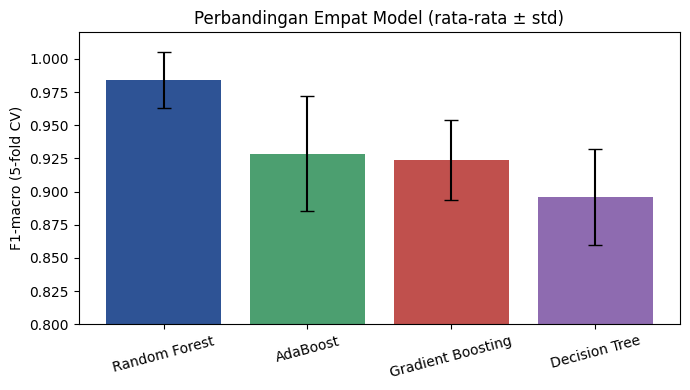

In [8]:
# Skor per fold + visualisasi
print(pd.DataFrame(semua_skor, index=[f"Fold {i}" for i in range(1, 6)]).round(3))

plt.figure(figsize=(7, 4))
urut = tabel["Model"].tolist()
plt.bar(urut, tabel["F1-macro rata-rata"], yerr=tabel["Std"], capsize=5,
        color=["#2E5395", "#4C9F70", "#C0504D", "#8E6BB0"])
plt.ylim(0.8, 1.02); plt.ylabel("F1-macro (5-fold CV)")
plt.title("Perbandingan Empat Model (rata-rata ± std)")
plt.xticks(rotation=15)
plt.tight_layout(); plt.show()

**Kesimpulan Latihan 2:**

| Model | F1-macro rata-rata (5-fold) | Std |
|---|---|---|
| Random Forest | **0,984** | 0,021 |
| AdaBoost | 0,929 | 0,044 |
| Gradient Boosting | 0,924 | 0,030 |
| Decision Tree | 0,896 | 0,036 |

1. **Random Forest terbaik dan paling stabil.** Rata-ratanya tertinggi, simpangan bakunya terendah, dan pada skor per fold ia tertinggi atau seri di kelima fold.
2. **Ensemble mengungguli satu pohon.** Ketiganya meningkatkan F1-macro sekitar 3 hingga 9 poin dibanding Decision Tree tunggal. Ini menegaskan manfaat menggabungkan banyak model lemah.
3. **AdaBoost dan Gradient Boosting setara.** Selisih 0,005 jauh lebih kecil daripada simpangan baku masing-masing (0,030–0,044), jadi tidak dapat dikatakan salah satunya lebih baik. AdaBoost juga paling tidak stabil (std 0,044; skor fold terendah 0,864).
4. **Rekomendasi:** untuk dataset Wine, gunakan **Random Forest** (akurat, stabil, hampir tanpa tuning). **Catatan:** boosting di sini memakai hyperparameter default; dengan tuning (`learning_rate`, `max_depth`, `n_estimators`) kesenjangannya bisa menyempit, dan dataset kecil (178 sampel) membuat estimasi CV cukup berfluktuasi.